In [138]:
import cv2
import pytesseract
import matplotlib.pyplot as plt
import numpy as np

pytesseract.pytesseract.tesseract_cmd = r'C:\Program Files\Tesseract-OCR\tesseract.exe'
print(pytesseract.get_tesseract_version())

5.5.3.20260724


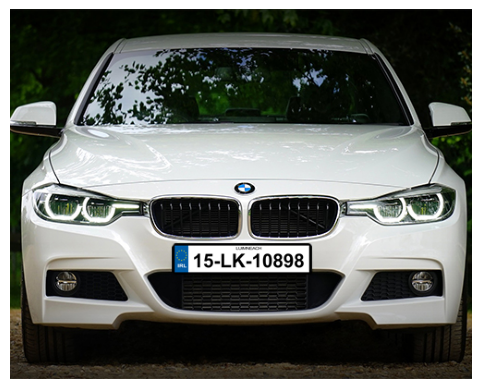

In [139]:
#Image check (test)
image = cv2.imread("car.png")
true_reading = "15LK10898"
plt.imshow(image)

plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [140]:
# pass in BGR IMAGE not RGB IMAGE
def OCR_detection(image,show_detected_plate=False,show_cropped_plate=False):
    # STEP 1: Convert image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # STEP 2: Reduce noise
    blurred = cv2.bilateralFilter(gray, 11, 17, 17)

    # STEP 3: Detect edges
    edges = cv2.Canny(blurred, 30, 200)

    # STEP 4: Find contours
    contours, _ = cv2.findContours(
        edges,
        cv2.RETR_LIST,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Sort contours by area
    contours = sorted(
        contours,
        key=cv2.contourArea,
        reverse=True
    )[:50]

    # STEP 5: Locate license plate
    plate_contour = None

    for contour in contours:
        perimeter = cv2.arcLength(contour, True)

        approx = cv2.approxPolyDP(
            contour, 0.02 * perimeter, True
        )

        # Look for rectangular contours
        if len(approx) == 4 and cv2.isContourConvex(approx):
            x, y, w, h = cv2.boundingRect(approx)

            aspect_ratio = w / h

            # Filter for license plate proportions
            if 2 < aspect_ratio < 6 and w > 60 and h > 15:
                plate_contour = (x, y, w, h)
                break

    # STEP 6: Crop detected plate
    if plate_contour is not None:
        x, y, w, h = plate_contour

        plate = image[y:y+h, x:x+w]

        # Draw rectangle around detected plate
        result = image.copy()
        cv2.rectangle(
            result,
            (x, y),
            (x+w, y+h),
            (0, 255, 0),
            2
        )

        if (show_detected_plate):    
            plt.figure(figsize=(12, 5))
            plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
            plt.title("Detected License Plate")
            plt.axis("off")
            plt.show()

        # STEP 7: Prepare plate for OCR
        plate_gray = cv2.cvtColor(
            plate, cv2.COLOR_BGR2GRAY
        )

        plate_gray = cv2.resize(
            plate_gray,
            None,
            fx=2,
            fy=2,
            interpolation=cv2.INTER_CUBIC
        )

        _, thresh = cv2.threshold(
            plate_gray,
            0,
            255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        # STEP 8: Read license plate
        config = "--psm 7 -c tessedit_char_whitelist=ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"

        text = pytesseract.image_to_string(
            thresh,
            config=config
        )

        if (show_cropped_plate):
            plt.figure(figsize=(8, 3))
            plt.imshow(thresh, cmap="gray")
            plt.title("Cropped License Plate")
            plt.axis("off")
            plt.show()

        license_plate_text = text.strip()
        return(license_plate_text)

    else:
        return("No license plate detected.")


blur detection: No license plate detected.


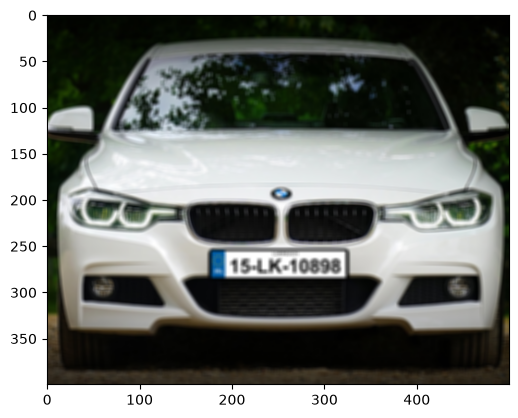

In [141]:
blur_image = cv2.GaussianBlur(image, (5, 5), 10)
plt.imshow(cv2.cvtColor(blur_image, cv2.COLOR_BGR2RGB))
blurry_detection = OCR_detection(blur_image, show_detected_plate=True, show_cropped_plate=True)
print("blur detection: " + blurry_detection)

Unblurring via sharpening

In [142]:
def kernel_sharpen(img):
    img = img.astype(np.float32)

    kernel = np.array([[0, -1, 0],
                       [-1, 5, -1],
                       [0, -1, 0]], dtype=np.float32)
    sharpened = cv2.filter2D(img, ddepth=-1, kernel=kernel)
    sharpened = np.clip(sharpened, 0,255).astype(np.uint8)
    return sharpened

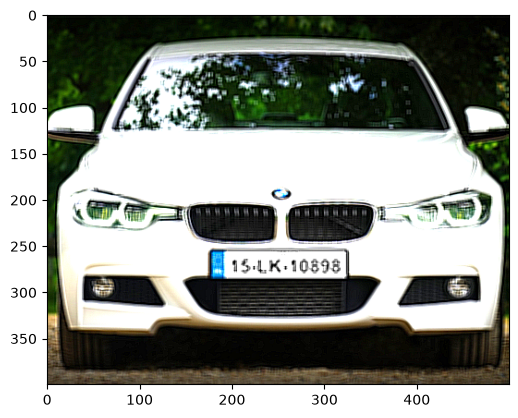

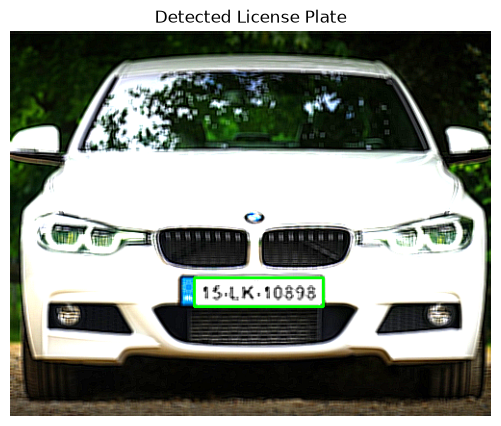

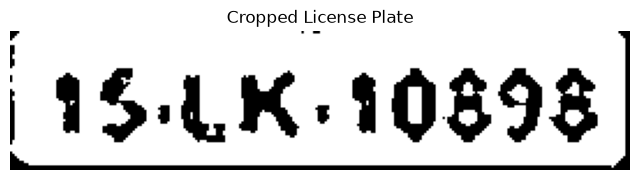

sharp detection: 15LK10898


In [143]:
# note, had to play around with center value of kernel to get a good detection. 
sharpen_kernel = np.array([[-1,-1,-1], [-1,9.75,-1], [-1,-1,-1]])
sharpen = cv2.filter2D(blur_image, -1, sharpen_kernel)
plt.imshow(cv2.cvtColor(sharpen, cv2.COLOR_BGR2RGB))
sharp_detection = OCR_detection(sharpen,show_detected_plate=True, show_cropped_plate=True)
print("sharp detection: " + sharp_detection)

#potential takeaways: 
# run sharping before OCR deteciton on non-blurred images as well?
# iterate over different sharpening kernels to see if license plate can be detected?
# potentially use something like a gridsearch to fine tune sharpening kernel?
# main value that seems to matter in kernel is the center value, needs more testing on more images.  

In [144]:
print("read from image = true reading?: " + str(sharp_detection == true_reading))

read from image = true reading?: True


Unblur via Laplacian

In [145]:
def laplacian_sharpen(img, alpha=0.5):
    """
    Laplacian-based sharpening:
    - Compute Laplacian (second derivative)
    - Subtract scaled Laplacian from the image
    """
    img = img.astype(np.float32)
    lap = cv2.Laplacian(img, cv2.CV_32F, ksize=3)
    sharpened = img - alpha * lap
    sharpened = np.clip(sharpened, 0, 255).astype(np.uint8)
    return sharpened

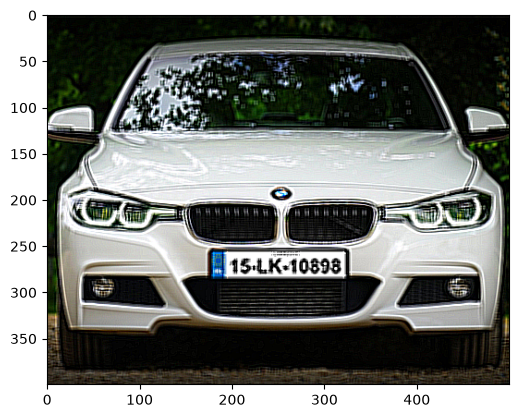

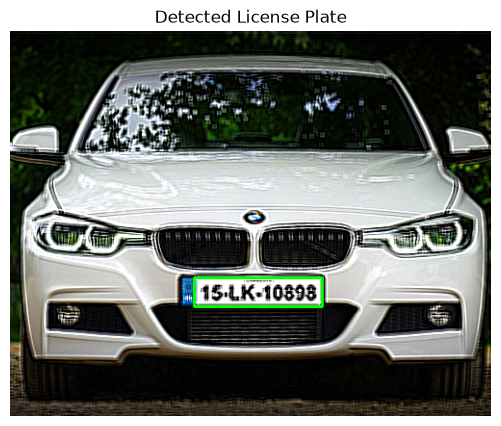

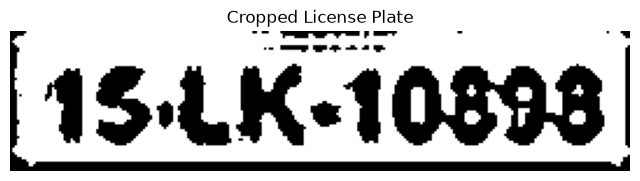

laplacian detection: 15LK10898


In [146]:
# note, had to play around with alpha value of lapclacian to get a good detection. 
laplacian = laplacian_sharpen(blur_image, alpha=1.25)
plt.imshow(cv2.cvtColor(laplacian, cv2.COLOR_BGR2RGB))
laplacian_detection = OCR_detection(laplacian,show_detected_plate=True, show_cropped_plate=True)
print("laplacian detection: " + laplacian_detection)

#potential takeaways:   

In [147]:
print("read from image = true reading?: " + str(laplacian_detection == true_reading))

read from image = true reading?: True


Unblur via unsharpening mask

In [148]:
def unsharp_mask(img, sigma=2.0, amount=1.5):
    img = img.astype(np.float32)
    blur = cv2.GaussianBlur(img, (0, 0), sigmaX=sigma, sigmaY=sigma)
    detail = img - blur
    sharpened = img + amount * detail
    sharpened = np.clip(sharpened, 0,255).astype(np.uint8)
    return sharpened

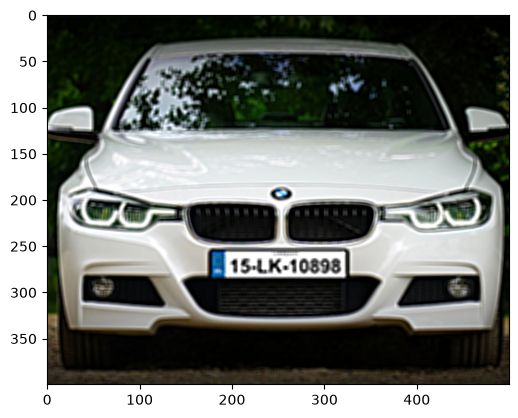

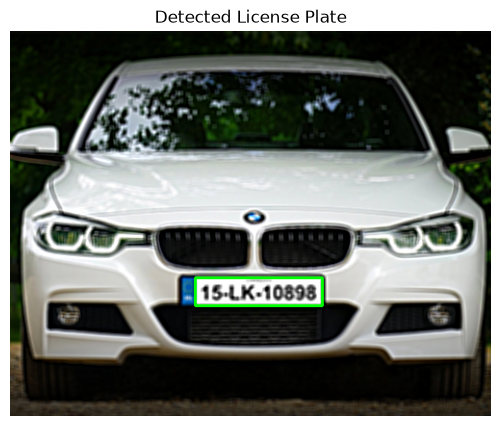

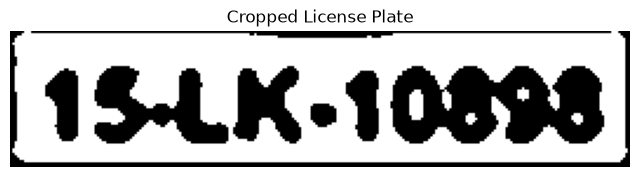

unsharp detection: 15LK10898


In [149]:
# note, had to play around with alpha value of lapclacian to get a good detection. 
unsharp = unsharp_mask(blur_image)
plt.imshow(cv2.cvtColor(unsharp, cv2.COLOR_BGR2RGB))
unsharp_detection = OCR_detection(unsharp,show_detected_plate=True, show_cropped_plate=True)
print("unsharp detection: " + unsharp_detection)

#potential takeaways:   

In [150]:
print("read from image = true reading?: " + str(laplacian_detection == true_reading))

read from image = true reading?: True
